# Statistical arbitrage: trading the gap between two cointegrated stocks
**William Caron-Bastarache** — Case study 2, PolyFinances (RITC team selection)

## Summary

**Question:** among nine stocks (2015–2024), is there a pair whose price gap keeps returning to a stable level, and can a profitable strategy be built on it?

**Answer: yes, DDD and HHH.** The rules were set using 2015–2019 data only, then tested once on 2020–2024. Over that period, they turn \$100,000 into **\$126,597**.

| DDD–HHH strategy | 2015–2019 (construction period) | **2020–2024 (out-of-sample test)** | Market, 2020–2024 (benchmark) |
|---|---|---|---|
| Total return | +40.6% | **+26.6%** | +99.1% |
| Annualized return | +7.1% | **+4.8%** | +14.8% |
| Annualized volatility | 4.5% | **3.7%** | 12.5% |
| Sharpe ratio | 1.54 | **1.28** | 1.16 |
| Maximum drawdown | −4.2% | **−5.9%** | −17.9% |
| Trades (winners) | 10 (10) | **8 (7)** | — |

*Market: equal-weighted portfolio of the nine stocks. Full risk measures in section 6.*

**Key takeaways:**
1. **Only one pair is truly cointegrated.** Out of 36 pairs tested, DDD–HHH has a p-value below 10⁻⁵. The runner-up, BBB–CCC (p = 0.03), does not survive a multiple-testing correction: with 36 tests, about 2 false positives are expected at the 5% level. BBB–CCC is no longer cointegrated in 2020–2024, while DDD–HHH still is (section 6.2).
2. **The relationship is stable.** The hedge ratio estimated on 2015–2019 (0.791) is almost identical to the one estimated on 2020–2024 alone (0.791). The gap closes halfway to its mean in about 14 trading days.
3. **The profit comes from the pair, not from luck or the market.** The same rules applied to the other 35 pairs give a median Sharpe of 0.13, and several wipe out the capital. The strategy has almost no correlation with the market (0.03).
4. **The result is modest and should be read as such:** few trades (8 in five years), capital deployed only 16% of the time, and data that are most likely synthetic. The result depends little on costs and on the chosen thresholds (section 6.4).

### How this notebook answers the brief

| Brief item | Section |
|---|---|
| 1. Explore the data and check its quality | 2 |
| 2. Identify a cointegrated pair with statistical tests and justify the choice | 3 |
| 3. Build the spread and plot its evolution | 4 |
| 4. Define the strategy: entry, exit, positions, size | 5 |
| 5. Simulate the strategy, report P&L and performance and risk measures | 5.3 (2015–2019) and 6 (2020–2024) |
| 6. Assumptions and limitations | 7 (summary table) and 8 |

### Vocabulary

- **Cointegration**: two prices that each wander randomly, but a combination of which (the *spread*) always returns to a mean. They can drift apart temporarily, but a force pulls them back together.
- **Spread**: here, $\ln(\text{DDD}) - \beta \ln(\text{HHH}) - \alpha$. It is the gap between DDD and what HHH "predicts" for DDD.
- **Hedge ratio** ($\beta$): how many dollars of HHH to sell for each dollar of DDD bought so that the position depends only on the spread.
- **Z-score**: the spread measured in standard deviations from its mean. A z-score of +2 means DDD is unusually expensive relative to HHH.
- **Half-life**: the typical time for the spread to cover half the distance back to its mean.
- **Out of sample**: data that were not used for any decision. It is the only honest way to measure a strategy.
- **Drawdown**: the drop in capital from its previous peak. The **maximum drawdown** is the worst such drop.

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)   # statsmodels version notice, no effect here
warnings.filterwarnings("ignore", category=np.exceptions.ComplexWarning)   # internal warning of the Johansen test
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.formatter.use_mathtext"] = False

initial_capital = 100_000.0
DATA_PATH = "data.csv"

# Time split (section 1): decisions use the formation period, the test period is only for measuring
FORMATION = slice("2015-01-01", "2019-12-31")
TEST = slice("2020-01-01", "2024-12-31")

DAYS_PER_YEAR = 261     # business days per year in this file (section 2.1)
COST = 0.0005           # transaction cost: 0.05% of traded value, per leg and per transaction

COLORS = {"DDD": "#2a78d6", "HHH": "#eb6834", "Strategy": "#0b0b0b", "Market": "#9a9893", "BBB–CCC": "#e87ba4"}
GRAY = "#52514e"
SHADE = "#e6e5e0"

def style_ax(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=SHADE, linewidth=0.8)
    ax.set_axisbelow(True)

def shade_test(ax, label=True):
    # Gray band = test period (2020–2024)
    ax.axvspan(pd.Timestamp(TEST.start), pd.Timestamp(TEST.stop), color=SHADE, zorder=0,
               label="Test (out of sample)" if label else None)

def fmt_p(p):
    # Readable p-value: scientific notation when it is tiny
    return f"{p:.4f}" if p >= 1e-4 else f"{p:.0e}"

## 1. The data

The file `data.csv` contains the daily closing price of nine stocks, named AAA to III, from 2015 to 2024. The brief mentions an unnamed index first column: it is dropped if present.

**Rule: time is split in two.**

| Period | Years | Role |
|---|---|---|
| **Formation** | 2015–2019 | Choose the pair, estimate the spread, set the trading rules |
| **Test** | 2020–2024 | Simulate the strategy with **frozen** rules. No decision uses this data |

If the pair and thresholds were chosen by looking at all ten years, the reported profit would be inflated: we would have picked, after the fact, what worked. With this split, section 6 measures what a trader would really have earned by applying, in early 2020, what was known at the end of 2019.

In [2]:
data = pd.read_csv(DATA_PATH)
data = data.loc[:, ~data.columns.str.startswith("Unnamed")]      # unnamed index mentioned in the brief
data["Date"] = pd.to_datetime(data["Date"])
prices = data.set_index("Date").sort_index()
TICKERS = list(prices.columns)

print(f"{len(prices):,} days, from {prices.index.min().date()} to {prices.index.max().date()}, {len(TICKERS)} stocks: {', '.join(TICKERS)}")
print(f"Formation: {len(prices.loc[FORMATION]):,} days   Test: {len(prices.loc[TEST]):,} days")
prices.head()

2,609 days, from 2015-01-01 to 2024-12-31, 9 stocks: AAA, BBB, CCC, DDD, EEE, FFF, GGG, HHH, III
Formation: 1,304 days   Test: 1,305 days


,AAA,BBB,CCC,DDD,EEE,FFF,GGG,HHH,III
Date,,,,,,,,,
2015-01-01,27.17,157.98,51.60,163.89,65.40,303.36,138.56,110.07,13.11
2015-01-02,27.40,159.89,53.07,164.71,65.52,307.91,138.57,108.35,13.12
2015-01-05,27.42,160.64,52.89,168.29,66.51,306.24,141.76,111.49,13.08
2015-01-06,27.00,157.56,51.21,168.94,66.10,299.58,139.11,112.61,12.88
2015-01-07,27.44,158.94,52.90,173.07,66.46,297.88,139.53,116.42,13.08


## 2. Data inspection

Before testing anything, we check that the prices are reliable. A single error (a zero price, an unadjusted stock split, a duplicated day) is enough to create a false trading signal. We look at four things: structure, calendar, abnormal returns and stale prices.

### 2.1 Structure and calendar

In [3]:
gaps = prices.index.to_series().diff().dt.days
per_year = prices.groupby(prices.index.year).size()
holidays = [d for d in ["2015-12-25", "2016-01-01", "2019-07-04", "2020-12-25"] if pd.Timestamp(d) in prices.index]

checks = pd.Series({
    "Missing values": int(prices.isna().sum().sum()),
    "Duplicate dates": int(prices.index.duplicated().sum()),
    "Dates in order": prices.index.is_monotonic_increasing,
    "Zero or negative prices": int((prices <= 0).sum().sum()),
    "Weekend days": int((prices.index.dayofweek >= 5).sum()),
    "Largest gap between two dates (days)": int(gaps.max()),
    "Days per year (min–max)": f"{per_year.min()}–{per_year.max()}",
    "Holidays present (e.g.)": ", ".join(holidays),
}, name="Result")
checks.to_frame()

,Result
Missing values,0
Duplicate dates,0
Dates in order,True
Zero or negative prices,0
Weekend days,0
Largest gap between two dates (days),3
Days per year (min–max),260–262
Holidays present (e.g.),"2015-12-25, 2016-01-01, 2019-07-04, 2020-12-25"


- **No missing values, no duplicates, no zero or negative prices.** Dates are in order.
- **The calendar contains every weekday**, including Christmas and New Year's Day, i.e. 260 to 262 days per year. Real exchanges are closed on those days (about 252 trading days per year). This is a first sign that the data are **synthetic**. Practical consequence: we annualize with **261 days**, not 252.
- So there is **nothing to clean** in the structure. The prices themselves remain to be checked.

### 2.2 Abnormal returns and stale prices

An unadjusted stock split (e.g. 2-for-1) would make the price drop 50% in one day. A "stale" price (identical several days in a row) would point to copied data.

In [4]:
returns = np.log(prices).diff().dropna()

def longest_flat_run(s):
    # Longest run of consecutive days with no price change
    flat = s.diff().eq(0)
    return int(flat.groupby((~flat).cumsum()).sum().max())

quality = pd.DataFrame({
    "Min price": prices.min(),
    "Max price": prices.max(),
    "Mean annual return (%)": 100 * returns.mean() * DAYS_PER_YEAR,
    "Annual volatility (%)": 100 * returns.std() * np.sqrt(DAYS_PER_YEAR),
    "Worst day (%)": 100 * returns.min(),
    "Best day (%)": 100 * returns.max(),
    "Days with no change": (prices.diff() == 0).sum(),
    "Longest stale run": prices.apply(longest_flat_run),
})
quality

,Min price,Max price,Mean annual return (%),Annual volatility (%),Worst day (%),Best day (%),Days with no change,Longest stale run
AAA,18.38,306.28,23.41,29.69,-6.55,6.27,1,1
BBB,135.72,785.11,15.35,20.76,-4.77,4.47,3,1
CCC,48.39,460.05,21.07,27.00,-5.39,5.32,2,1
DDD,120.11,328.76,2.82,25.55,-5.13,5.85,4,1
EEE,61.91,583.03,20.53,17.49,-3.52,3.40,7,1
FFF,129.18,483.61,-2.03,26.18,-5.74,6.58,2,1
GGG,84.91,187.52,2.39,20.75,-3.92,4.60,6,1
HHH,77.79,283.95,3.97,36.38,-6.97,8.07,2,1
III,12.77,119.52,22.12,24.48,-4.78,5.52,22,1


- **No suspicious jumps.** The worst day is about −7% and the best about +8% (HHH). Nothing looks like a split or a data-entry error.
- **Few stale prices**, never two unchanged days in a row. III has a few more (22) because its price is low (\$13 to \$120): with two decimals, a small move rounds to zero. This is normal.
- Volatilities (17% to 36% per year) are realistic for stocks.

### 2.3 Price overview

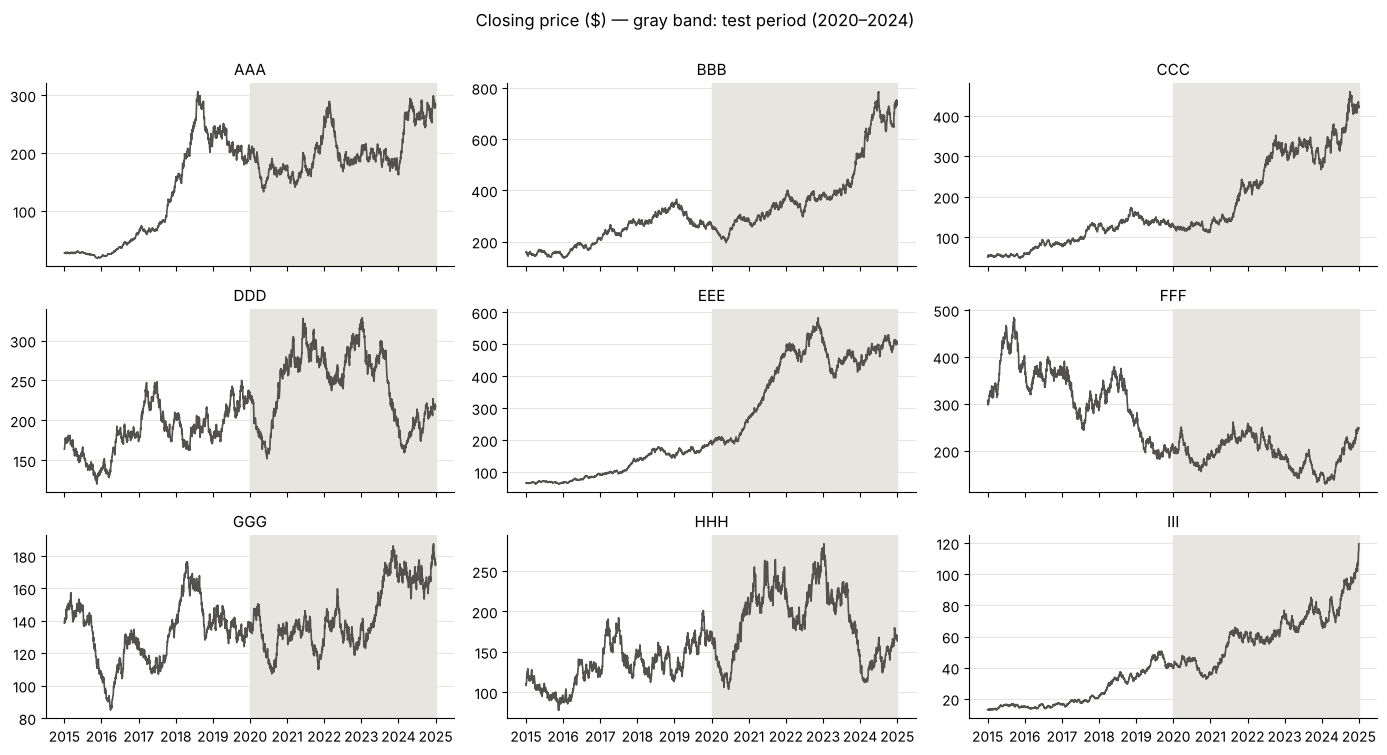

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(14, 7.5), sharex=True)
for ax, t in zip(axes.flat, TICKERS):
    ax.plot(prices.index, prices[t], color=GRAY, linewidth=1.2)
    ax.set_title(t, fontsize=11)
    shade_test(ax, label=False)
    style_ax(ax)
fig.suptitle(r"Closing price (\$) — gray band: test period (2020–2024)", y=1.0)
plt.tight_layout(); plt.show()

The nine stocks follow very different paths. Two curves look alike to the eye: **DDD and HHH** (same trough in 2018, same peak in 2022, same drop in 2023). But two curves that look alike are not necessarily cointegrated: section 3 tests that.

### 2.4 Return correlation (2015–2019)

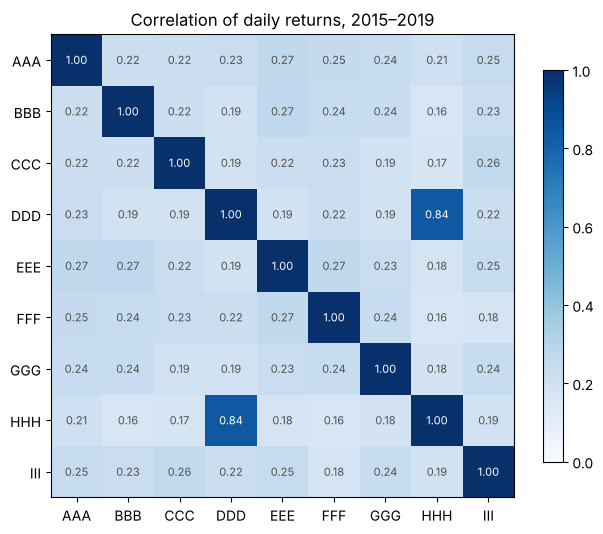

Most correlated pair: DDD and HHH (0.84)
Other pairs         : from 0.16 to 0.27


In [6]:
corr = returns.loc[FORMATION].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(TICKERS)), TICKERS)
ax.set_yticks(range(len(TICKERS)), TICKERS)
for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if corr.iloc[i, j] > 0.6 else GRAY)
ax.set_title("Correlation of daily returns, 2015–2019")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

off_diag = corr.where(~np.eye(len(TICKERS), dtype=bool)).stack()
print(f"Most correlated pair: {' and '.join(off_diag.idxmax())} ({off_diag.max():.2f})")
print(f"Other pairs         : from {off_diag.drop(off_diag.idxmax()).min():.2f} to {off_diag.drop([off_diag.idxmax(), off_diag.idxmax()[::-1]]).max():.2f}")

DDD and HHH have a correlation of 0.84; all other pairs are between 0.16 and 0.27, a typical level for two stocks that only share the influence of the market. DDD and HHH are most likely two companies in the same sector.

**Caution: correlation and cointegration are not the same thing.** Correlation measures whether two stocks move in the same direction **on the same day**. Cointegration measures whether their **prices** stay linked **in the long run**. Two highly correlated stocks can slowly drift apart (no cointegration), and two stocks with low day-to-day correlation can stay linked in the long run. Correlation gives a lead; only a cointegration test can decide.

### 2.5 Inspection summary

| Finding | Decision |
|---|---|
| No missing values, no duplicates, no aberrant prices | No cleaning needed |
| Calendar of 261 days per year, holidays included (synthetic data) | Annualize with 261 days |
| No suspicious price jump (split, error) | Prices used as is |
| Rare stale prices (two-decimal rounding for III) | No consequence |
| DDD and HHH highly correlated (0.84) | Lead to be confirmed by a cointegration test |

## 3. Choosing the pair (2015–2019 only)

We work with the **logarithm** of prices. The spread then reads as a percentage, and the hedge ratio becomes a dollar ratio (section 4.1).

### 3.1 Is each price a random walk?

Cointegration only makes sense for **non-stationary** series: prices with no fixed level to return to. The augmented Dickey-Fuller (ADF) test checks this. Its null hypothesis is "the series has a unit root (random walk)". A high p-value means we cannot reject it.

In [7]:
log_prices = np.log(prices)
form = log_prices.loc[FORMATION]

adf_table = pd.DataFrame({
    "ADF p-value: log price": [adfuller(form[t])[1] for t in TICKERS],
    "ADF p-value: returns": [adfuller(form[t].diff().dropna())[1] for t in TICKERS],
}, index=TICKERS)
adf_table.style.format("{:.3f}").set_caption("ADF test on 2015–2019 (p < 0.05: stationary)")

,ADF p-value: log price,ADF p-value: returns
AAA,0.845,0.000
BBB,0.672,0.000
CCC,0.555,0.000
DDD,0.528,0.000
EEE,0.945,0.000
FFF,0.871,0.000
GGG,0.498,0.000
HHH,0.336,0.000
III,0.905,0.000


All nine log prices are **non-stationary** (p-values from 0.34 to 0.95), and their returns are stationary (p = 0.000). They are therefore "integrated of order 1", like most stock prices. We can test cointegration on every pair.

### 3.2 Cointegration test on all 36 pairs

**Engle-Granger test**: regress one log price on the other, then check with an ADF test whether the residual (the spread) is stationary. The null hypothesis is "no cointegration". The result depends slightly on the direction of the regression (A on B or B on A); we run both and keep the **larger** p-value, to be safe.

**The multiple-testing trap.** With 36 pairs and a 5% threshold, about 36 × 5% ≈ 2 pairs are expected to look "cointegrated" by pure chance, even if none is. To guard against this, we apply the **Bonferroni correction**: we require p < 0.05 / 36 ≈ 0.0014.

In [8]:
PAIRS = list(itertools.combinations(TICKERS, 2))
BONFERRONI = 0.05 / len(PAIRS)

rows = []
for a, b in PAIRS:
    p_ab = coint(form[a], form[b])[1]
    p_ba = coint(form[b], form[a])[1]
    rows.append({"Pair": f"{a}–{b}", "p (A on B)": p_ab, "p (B on A)": p_ba, "p kept": max(p_ab, p_ba),
                 "Return correlation": corr.loc[a, b]})
eg = pd.DataFrame(rows).set_index("Pair").sort_values("p kept")
eg["Cointegrated at 5%"] = np.where(eg["p kept"] < 0.05, "yes", "no")
eg["Cointegrated after Bonferroni"] = np.where(eg["p kept"] < BONFERRONI, "yes", "no")

print(f"Pairs cointegrated at 5%                       : {(eg['p kept'] < 0.05).sum()} out of {len(PAIRS)}")
print(f"Pairs cointegrated after Bonferroni (p < {BONFERRONI:.4f}) : {(eg['p kept'] < BONFERRONI).sum()}")
eg.head(8).style.format(fmt_p, subset=["p (A on B)", "p (B on A)", "p kept"]) \
    .format("{:.2f}", subset=["Return correlation"]).set_caption("Engle-Granger on 2015–2019: top 8 pairs")

Pairs cointegrated at 5%                       : 2 out of 36
Pairs cointegrated after Bonferroni (p < 0.0014) : 1


,p (A on B),p (B on A),p kept,Return correlation,Cointegrated at 5%,Cointegrated after Bonferroni
Pair,,,,,,
DDD–HHH,5e-06,3e-06,5e-06,0.84,yes,yes
BBB–CCC,0.0338,0.0286,0.0338,0.22,yes,no
AAA–CCC,0.1973,0.1220,0.1973,0.22,no,no
AAA–BBB,0.2363,0.1760,0.2363,0.22,no,no
FFF–HHH,0.2651,0.0615,0.2651,0.16,no,no
CCC–HHH,0.3257,0.1447,0.3257,0.17,no,no
FFF–III,0.3407,0.2391,0.3407,0.18,no,no
DDD–FFF,0.1688,0.3491,0.3491,0.22,no,no


- **DDD–HHH is the only pair cointegrated after correction**, with a p-value of about 5 × 10⁻⁶, hundreds of times below the threshold. The result does not depend on the direction of the regression.
- **BBB–CCC passes the 5% threshold (p ≈ 0.03), but not the correction.** This is exactly the false positive expected with 36 tests. Its day-to-day correlation (0.22) is no higher than that of the other pairs: nothing points to a particular economic link. We keep it aside as a **control**: if our reasoning is right, it should no longer be cointegrated in 2020–2024 (checked in 6.2).
- The other pairs are far from the threshold.

### 3.3 Confirmation with the Johansen test

The Johansen test is a second method, which treats both prices symmetrically (no "dependent" variable). It first tests "no cointegrating relationship" (r = 0), then "at most one" (r ≤ 1).

In [9]:
jo = coint_johansen(form[["DDD", "HHH"]], det_order=0, k_ar_diff=1)
pd.DataFrame({
    "Trace statistic": jo.lr1,
    "Critical value 95%": jo.cvt[:, 1],
    "Critical value 99%": jo.cvt[:, 2],
    "Hypothesis rejected": np.where(jo.lr1 > jo.cvt[:, 2], "yes (99%)", "no"),
}, index=["r = 0 (no relationship)", "r ≤ 1 (at most one)"])

,Trace statistic,Critical value 95%,Critical value 99%,Hypothesis rejected
r = 0 (no relationship),38.99,15.49,19.93,yes (99%)
r ≤ 1 (at most one),2.46,3.84,6.63,no


Johansen rejects "no relationship" at 99%, but not "at most one relationship". There is therefore **exactly one cointegrating relationship** between DDD and HHH, which confirms Engle-Granger.

**Choice: the DDD–HHH pair.** Four reasons:
1. It is the only pair significant after correcting for the 36 tests, and the only one significant under both methods.
2. Its p-value is so small that the choice does not depend on any threshold.
3. It is also by far the most correlated pair (0.84): the statistical link has a plausible economic counterpart (same sector).
4. The spread reverts quickly to its mean (half-life of 14 days, section 4.3): enough trading opportunities for a strategy.

## 4. The spread

### 4.1 Estimating the hedge ratio

We estimate, by least squares on 2015–2019:

$$\ln(\text{DDD}_t) = \alpha + \beta \, \ln(\text{HHH}_t) + \varepsilon_t$$

The **spread** is the residual $\varepsilon_t = \ln(\text{DDD}_t) - \beta \ln(\text{HHH}_t) - \alpha$. It measures, in percent, how far DDD is above (or below) its "normal" level relative to HHH.

**Why logs rather than prices?** With logs, the change in the spread is $r_{\text{DDD}} - \beta \, r_{\text{HHH}}$ (two returns). Holding \$1 of DDD and shorting \$$\beta$ of HHH therefore replicates the spread exactly, whatever the price level. With raw prices, the number of shares to hold would depend on the price level.

In [10]:
def fit_spread(y, x, period):
    # Regress ln(y) on ln(x) over `period`; returns (alpha, beta, model)
    model = sm.OLS(log_prices.loc[period, y], sm.add_constant(log_prices.loc[period, x])).fit()
    return model.params.iloc[0], model.params.iloc[1], model

ALPHA, BETA, ols = fit_spread("DDD", "HHH", FORMATION)
spread = log_prices["DDD"] - BETA * log_prices["HHH"] - ALPHA       # whole period, 2015–2019 parameters
MU, SIGMA = spread.loc[FORMATION].mean(), spread.loc[FORMATION].std()
zscore = (spread - MU) / SIGMA

print(f"alpha = {ALPHA:.4f}   beta = {BETA:.4f}   R² = {ols.rsquared:.3f}")
print(f"Spread over 2015–2019: mean {MU:.4f}, standard deviation {SIGMA:.4f} (a typical {SIGMA:.1%} gap between DDD and its 'normal' value)")

alpha = 1.3602   beta = 0.7910   R² = 0.964
Spread over 2015–2019: mean -0.0000, standard deviation 0.0310 (a typical 3.1% gap between DDD and its 'normal' value)


- **β = 0.79**: for each dollar of DDD bought, we short \$0.79 of HHH. HHH is more volatile than DDD (36% vs 25% per year), so less of it is needed to hedge the same risk.
- **R² = 0.96**: HHH explains almost all of DDD's movements.
- The spread's standard deviation is about **3%**. A z-score of 2 therefore means DDD is about 6% too expensive (or too cheap) relative to HHH.

### 4.2 Evolution of the spread

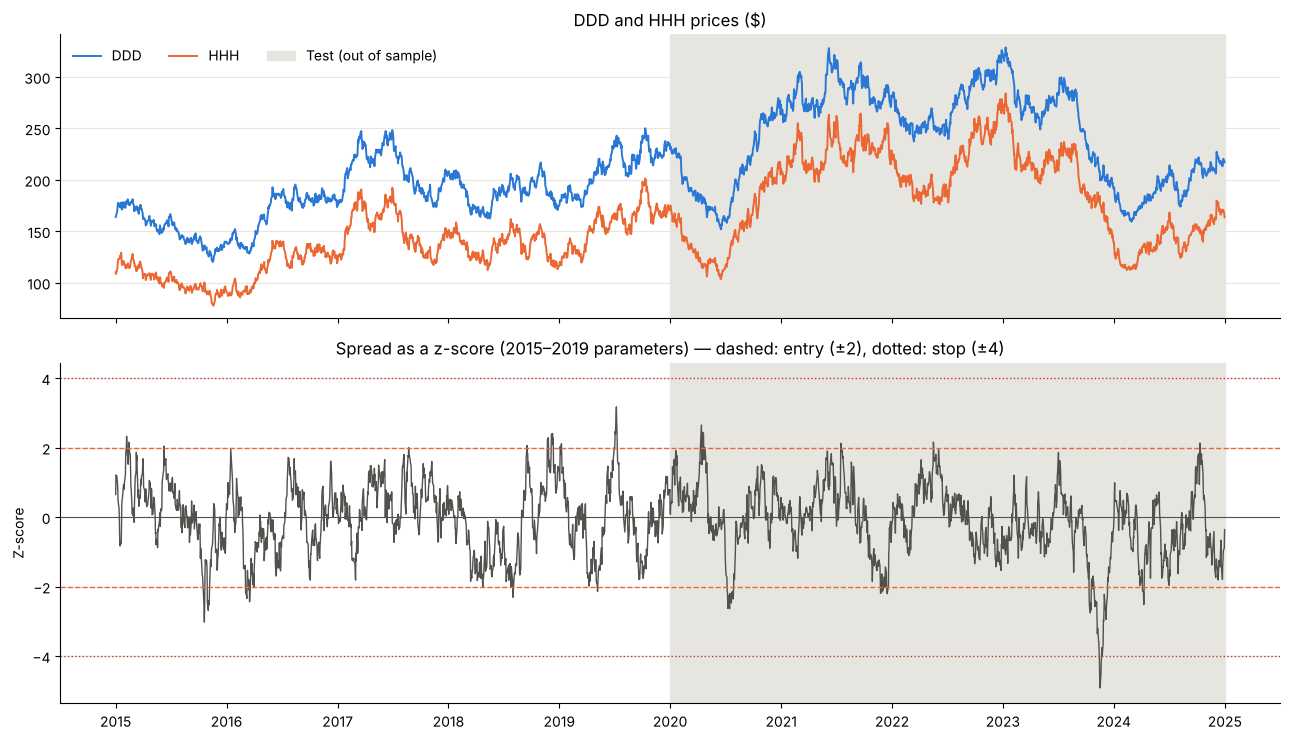

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})

ax = axes[0]
for t in ["DDD", "HHH"]:
    ax.plot(prices.index, prices[t], color=COLORS[t], linewidth=1.4, label=t)
shade_test(ax)
ax.set_title(r"DDD and HHH prices (\$)")
ax.legend(frameon=False, ncol=3, loc="upper left")
style_ax(ax)

ax = axes[1]
ax.plot(zscore.index, zscore, color=GRAY, linewidth=1)
for level, style in [(2, "--"), (-2, "--"), (4, ":"), (-4, ":")]:
    ax.axhline(level, color=COLORS["HHH"] if abs(level) == 2 else "#c0392b", linestyle=style, linewidth=1)
ax.axhline(0, color=GRAY, linewidth=0.8)
shade_test(ax, label=False)
ax.set_ylabel("Z-score")
ax.set_title("Spread as a z-score (2015–2019 parameters) — dashed: entry (±2), dotted: stop (±4)")
style_ax(ax)
plt.tight_layout(); plt.show()

- Even though prices double and then fall, **the spread oscillates around zero** for the full ten years. That is what cointegration means.
- It crosses ±2 several times a year, then comes back. These are the trading opportunities.
- **In 2020–2024 (gray band), the 2019 parameters keep working**: the spread stays centered, with no drift. One episode stands out: in late 2023, the z-score falls to about −4.9, further than anything seen in formation (minimum of −3.0). This is the strategy's stress test (section 6.1).

### 4.3 How fast does the spread revert?

We estimate $\Delta \varepsilon_t = c + \lambda \, \varepsilon_{t-1} + u_t$. If $\lambda < 0$, the spread is pulled toward its mean, and the **half-life** is $-\ln 2 / \ln(1 + \lambda)$.

Spread half-life (2015–2019): 13.6 trading days (about 3 weeks)
Days with |z| > 2 in formation: 3.5%
Extreme z-score in formation  : from -3.02 to 3.18


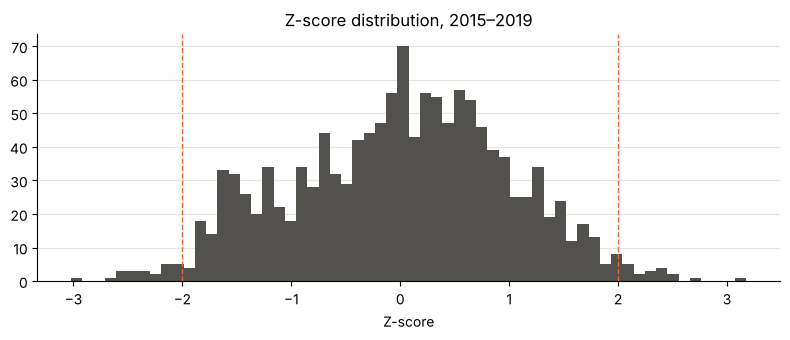

In [12]:
def half_life(s):
    s = s.dropna()
    lam = sm.OLS(s.diff().iloc[1:], sm.add_constant(s.shift(1).iloc[1:])).fit().params.iloc[1]
    return -np.log(2) / np.log(1 + lam)

HALF_LIFE = half_life(spread.loc[FORMATION])
share_beyond_2 = (zscore.loc[FORMATION].abs() > 2).mean()
print(f"Spread half-life (2015–2019): {HALF_LIFE:.1f} trading days (about {HALF_LIFE / 5:.0f} weeks)")
print(f"Days with |z| > 2 in formation: {share_beyond_2:.1%}")
print(f"Extreme z-score in formation  : from {zscore.loc[FORMATION].min():.2f} to {zscore.loc[FORMATION].max():.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(zscore.loc[FORMATION], bins=60, color=GRAY)
for level in [-2, 2]:
    ax.axvline(level, color=COLORS["HHH"], linestyle="--", linewidth=1)
ax.set_title("Z-score distribution, 2015–2019")
ax.set_xlabel("Z-score")
style_ax(ax)
plt.tight_layout(); plt.show()

- **Half-life of about 14 trading days** (3 weeks): a gap closes within a few weeks. Fast enough to trade, and slow enough that transaction costs do not eat everything.
- The z-score is beyond ±2 about 3.5% of the time (a bit less than the 4.6% of a normal distribution). It never went beyond ±3.2 in formation.

## 5. The strategy

### 5.1 Rules

All rules are set **before** looking at 2020–2024, based on standard values and on what was observed in formation.

| Element | Rule | Rationale |
|---|---|---|
| **Signal** | Spread z-score, with α, β, mean and standard deviation from 2015–2019, **never re-estimated** | No information from the future; stability is checked in 6.2 |
| **Entry** | z ≥ +2: **sell the spread** (sell DDD, buy HHH). z ≤ −2: **buy the spread** (buy DDD, sell HHH) | 2 standard deviations: about 3.5% of days in formation, so a truly unusual gap, but one that happens a few times a year |
| **Exit (target)** | The z-score crosses 0 | The spread is back to its mean: the gap has fully closed |
| **Exit (stop)** | \|z\| ≥ 4 | Never seen in formation (max 3.2). At 4, the relationship may be broken: cut the loss |
| **After a stop** | No new entry until \|z\| is back below 2 | Avoid immediately re-entering a relationship that may be broken |
| **Execution** | Signal computed at day *t* close, executed at day *t + 1* close | No look-ahead: one cannot trade at the price used to decide |
| **Positions** | One position at a time, on the DDD–HHH pair | Simplicity |

**Position size.** At each entry, **100% of capital** is committed (gross exposure), split according to β so that the position replicates the spread:
- DDD leg: $N = \text{capital} / (1 + \beta)$, about 56% of capital;
- HHH leg: $\beta N$, about 44% of capital, in the opposite direction.

The profit or loss is then roughly $N \times \Delta\text{spread}$. A z-score move from 2 back to 0 (a spread move of about 6%) therefore earns about 0.56 × 6% ≈ **3.4% of capital**. Quantities are rounded down to whole shares. The position is **nearly market-neutral**: net exposure is (1 − β) N ≈ 12% of capital, and the more volatile HHH offsets DDD's market risk.

**Costs.** 0.05% of traded value, per leg, at entry and exit (commission and bid-ask spread). The borrowing cost of shorted shares and interest on idle cash are set to zero; their effect is tested in 6.4.

In [13]:
def backtest(y, x, z, beta, entry=2.0, exit=0.0, stop=4.0, cost=COST, borrow=0.0, capital=initial_capital):
    '''Simulates the strategy over the period covered by `z` (z-score of the spread y − beta·x).

    Signal at close t, execution at close t+1. `beta` is a number or a series
    (value read on the entry day). Returns (daily capital, daily position, trades).
    position: +1 = spread bought (long y, short x), −1 = spread sold, 0 = flat.'''
    py, px = prices.loc[z.index, y].values, prices.loc[z.index, x].values
    zz, dates = z.values, z.index
    beta_at = (lambda t: beta) if np.isscalar(beta) else (lambda t: beta.loc[dates[t]])

    eq, pos, target, blocked = capital, 0, 0, False
    sh_y = sh_x = 0.0
    equity, position, trades, trade = np.empty(len(z)), np.zeros(len(z)), [], None

    for t in range(len(z)):
        # 1. Daily P&L on the position held (and borrowing cost of the short leg)
        if t > 0 and pos != 0:
            eq += sh_y * (py[t] - py[t - 1]) + sh_x * (px[t] - px[t - 1])
            short_value = -min(sh_y * py[t - 1], 0) - min(sh_x * px[t - 1], 0)
            eq -= borrow / DAYS_PER_YEAR * short_value

        # 2. Execute, at today's close, the decision taken yesterday
        if target != pos:
            if pos != 0:                                   # close
                eq -= cost * (abs(sh_y) * py[t] + abs(sh_x) * px[t])
                trade.update(exit=dates[t], z_exit=zz[t], capital_exit=eq)
                trades.append(trade)
                sh_y = sh_x = 0.0
            if target != 0 and eq > 0:                     # open
                b = beta_at(t)
                n = eq / (1 + b)
                sh_y = target * np.floor(n / py[t])
                sh_x = -target * np.floor(b * n / px[t])
                eq -= cost * (abs(sh_y) * py[t] + abs(sh_x) * px[t])
                trade = dict(entry=dates[t], side="buy spread" if target > 0 else "sell spread",
                             z_entry=zz[t], capital_entry=eq)
            pos = target if eq > 0 else 0

        if eq <= 0:                                        # ruin: stop everything
            eq, pos, target = 0.0, 0, 0
        equity[t], position[t] = eq, pos

        # 3. Decision for tomorrow, from tonight's z-score
        zt = zz[t]
        if pos == 0:
            if blocked and abs(zt) < entry:
                blocked = False
            if not blocked and eq > 0:
                target = -1 if entry <= zt < stop else (1 if -stop < zt <= -entry else 0)
        else:
            hit_target = (zt >= -exit) if pos > 0 else (zt <= exit)
            hit_stop = (zt <= -stop) if pos > 0 else (zt >= stop)
            if hit_target or hit_stop:
                target = 0
                trade["reason"] = "stop" if hit_stop else "target"
                blocked = hit_stop

    if pos != 0:                                           # position still open at the end: valued at the last price
        trade.update(exit=dates[-1], z_exit=zz[-1], capital_exit=eq, reason="end of period")
        trades.append(trade)

    trades = pd.DataFrame(trades)
    if len(trades):
        trades["P&L ($)"] = trades["capital_exit"] - trades["capital_entry"]
        trades["return"] = trades["capital_exit"] / trades["capital_entry"] - 1
        trades["duration (days)"] = [len(z.loc[a:b]) - 1 for a, b in zip(trades["entry"], trades["exit"])]
    return pd.Series(equity, dates), pd.Series(position, dates), trades

### 5.2 Performance and risk measures

| Measure | What it tells us |
|---|---|
| P&L, total return, annualized return | How much we earn |
| Annualized volatility | How much capital fluctuates |
| **Sharpe ratio** | Return per unit of risk (risk-free rate assumed zero). Above 1 is good; a market-neutral strategy often targets 1 to 2 |
| Sortino ratio | Like Sharpe, but only penalizes downside |
| **Maximum drawdown** and its duration | Worst loss from a peak, and how long it took to recover |
| Calmar ratio | Annualized return ÷ maximum drawdown |
| 95% VaR (1 day) | Daily loss exceeded only 1 day in 20 |
| Win rate, average gain and loss | Trade quality |
| Time in market | Share of days with capital deployed |
| Correlation and beta to the market | Is it really market-neutral? |

In [14]:
market_ret = prices.pct_change().mean(axis=1)            # equal-weighted portfolio of the 9 stocks (rebalanced daily)

def market_equity(period):
    r = market_ret.loc[period].copy()
    r.iloc[0] = 0.0
    return initial_capital * (1 + r).cumprod()

def metrics(equity, position=None, trades=None):
    r = equity.pct_change().dropna()
    years = len(r) / DAYS_PER_YEAR
    dd = equity / equity.cummax() - 1
    underwater = (dd < 0).astype(int)
    longest_dd = underwater.groupby((underwater == 0).cumsum()).sum().max()
    cagr = (equity.iloc[-1] / equity.iloc[0]) ** (1 / years) - 1
    downside = r[r < 0].std() * np.sqrt(DAYS_PER_YEAR)
    m = r.loc[market_ret.index.intersection(r.index)]
    mk = market_ret.loc[m.index]
    out = {
        "Final capital ($)": equity.iloc[-1],
        "P&L ($)": equity.iloc[-1] - equity.iloc[0],
        "Total return": equity.iloc[-1] / equity.iloc[0] - 1,
        "Annualized return": cagr,
        "Annualized volatility": r.std() * np.sqrt(DAYS_PER_YEAR),
        "Sharpe ratio": r.mean() / r.std() * np.sqrt(DAYS_PER_YEAR),
        "Sortino ratio": r.mean() * DAYS_PER_YEAR / downside,
        "Maximum drawdown": dd.min(),
        "Longest drawdown (days)": longest_dd,
        "Calmar ratio": cagr / -dd.min(),
        "95% VaR (1 day)": -r.quantile(0.05),
        "Worst day": r.min(),
        "Correlation with market": m.corr(mk),
        "Beta to market": m.cov(mk) / mk.var(),
    }
    if position is not None:
        out["Time in market"] = (position != 0).mean()
    if trades is not None and len(trades):
        out.update({
            "Number of trades": len(trades),
            "Win rate": (trades["P&L ($)"] > 0).mean(),
            "Average gain (winning trade)": trades.loc[trades["P&L ($)"] > 0, "return"].mean(),
            "Average loss (losing trade)": trades.loc[trades["P&L ($)"] <= 0, "return"].mean() if (trades["P&L ($)"] <= 0).any() else 0.0,
            "Average duration (days)": trades["duration (days)"].mean(),
        })
    return pd.Series(out)

METRIC_ORDER = ["Final capital ($)", "P&L ($)", "Total return", "Annualized return", "Annualized volatility",
                "Sharpe ratio", "Sortino ratio", "Maximum drawdown", "Longest drawdown (days)", "Calmar ratio",
                "95% VaR (1 day)", "Worst day", "Correlation with market", "Beta to market", "Time in market",
                "Number of trades", "Win rate", "Average gain (winning trade)", "Average loss (losing trade)",
                "Average duration (days)"]

FMT_PCT = ["Total return", "Annualized return", "Annualized volatility", "Maximum drawdown", "95% VaR (1 day)",
           "Worst day", "Time in market", "Win rate", "Average gain (winning trade)", "Average loss (losing trade)"]

def show_metrics(table, caption):
    fmt = {}
    for row in table.index:
        if row in FMT_PCT:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:.1%}"
        elif row in ["Final capital ($)", "P&L ($)"]:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:,.0f}"
        elif row in ["Number of trades", "Longest drawdown (days)"]:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:.0f}"
        else:
            fmt[row] = lambda v: "—" if pd.isna(v) else f"{v:.2f}"
    table = table.reindex([k for k in METRIC_ORDER if k in table.index])
    out = table.astype(object).copy()
    for row in out.index:
        out.loc[row] = [fmt[row](v) for v in table.loc[row]]
    display(out.style.set_caption(caption))

### 5.3 Result over the formation period (2015–2019)

This is an **in-sample** result: the pair and the spread were estimated on this same data. It checks that the mechanics work, not how good the strategy is (that is section 6's job).

In [15]:
eq_is, pos_is, trades_is = backtest("DDD", "HHH", zscore.loc[FORMATION], BETA)
m_is = metrics(eq_is, pos_is, trades_is)
show_metrics(m_is.to_frame("Strategy, 2015–2019"), "Formation (in sample)")

,"Strategy, 2015–2019"
Final capital ($),"140,624"
P&L ($),"40,624"
Total return,40.6%
Annualized return,7.1%
Annualized volatility,4.5%
Sharpe ratio,1.54
Sortino ratio,1.33
Maximum drawdown,-4.2%
Longest drawdown (days),356
Calmar ratio,1.69


To check that the chosen thresholds (entry 2, exit 0) are not a "lucky shot", we look at the formation Sharpe for other values. If 2 and 0 were an isolated peak, the strategy would be fragile.

In [16]:
ENTRIES, EXITS = [1.5, 1.75, 2.0, 2.25, 2.5], [-0.5, 0.0, 0.5, 1.0]

def sharpe_grid(period):
    grid = pd.DataFrame(index=[f"entry {e}" for e in ENTRIES], columns=[f"exit {x}" for x in EXITS], dtype=float)
    for e in ENTRIES:
        for x in EXITS:
            eq, _, _ = backtest("DDD", "HHH", zscore.loc[period], BETA, entry=e, exit=x)
            grid.loc[f"entry {e}", f"exit {x}"] = metrics(eq)["Sharpe ratio"]
    return grid

grid_is = sharpe_grid(FORMATION)
grid_is.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=2.5) \
    .set_caption("Formation Sharpe ratio by threshold (chosen rule: entry 2, exit 0)")

,exit -0.5,exit 0.0,exit 0.5,exit 1.0
entry 1.5,2.01,2.03,2.46,2.18
entry 1.75,1.71,1.72,1.93,1.68
entry 2.0,1.52,1.54,1.68,1.44
entry 2.25,1.23,1.39,1.27,1.17
entry 2.5,1.02,1.12,1.03,0.87


- In formation, the strategy wins every trade, with a Sharpe of 1.54. This is **not** a reliable measure: the pair was chosen *because* its spread reverted well over this period.
- **The chosen thresholds are not the best in formation**, on purpose: an entry threshold of 1.5 or 1.75 gave a higher Sharpe. Picking the table's maximum means optimizing on noise. We keep standard values (2 and 0), which sit on a plateau: every combination gives a positive Sharpe, between 0.87 and 2.46.
- High entry thresholds (2.5) give few trades: the z-score rarely reaches that level.

## 6. Out-of-sample result (2020–2024)

We now apply, **without changing anything**, the pair, β, the spread's mean and standard deviation, and the thresholds set with 2015–2019. We start with \$100,000 on January 1, 2020.

### 6.1 Profit, risk and trades

In [17]:
eq_oos, pos_oos, trades_oos = backtest("DDD", "HHH", zscore.loc[TEST], BETA)
eq_mkt = market_equity(TEST)

summary = pd.DataFrame({
    "Strategy, 2015–2019 (formation)": m_is,
    "Strategy, 2020–2024 (test)": metrics(eq_oos, pos_oos, trades_oos),
    "Market, 2020–2024": metrics(eq_mkt),
})
m_oos = summary["Strategy, 2020–2024 (test)"]
show_metrics(summary, "Performance and risk")

,"Strategy, 2015–2019 (formation)","Strategy, 2020–2024 (test)","Market, 2020–2024"
Final capital ($),"140,624","126,597","199,084"
P&L ($),"40,624","26,597","99,084"
Total return,40.6%,26.6%,99.1%
Annualized return,7.1%,4.8%,14.8%
Annualized volatility,4.5%,3.7%,12.5%
Sharpe ratio,1.54,1.28,1.16
Sortino ratio,1.33,0.95,2.05
Maximum drawdown,-4.2%,-5.9%,-17.9%
Longest drawdown (days),356,259,193
Calmar ratio,1.69,0.82,0.83


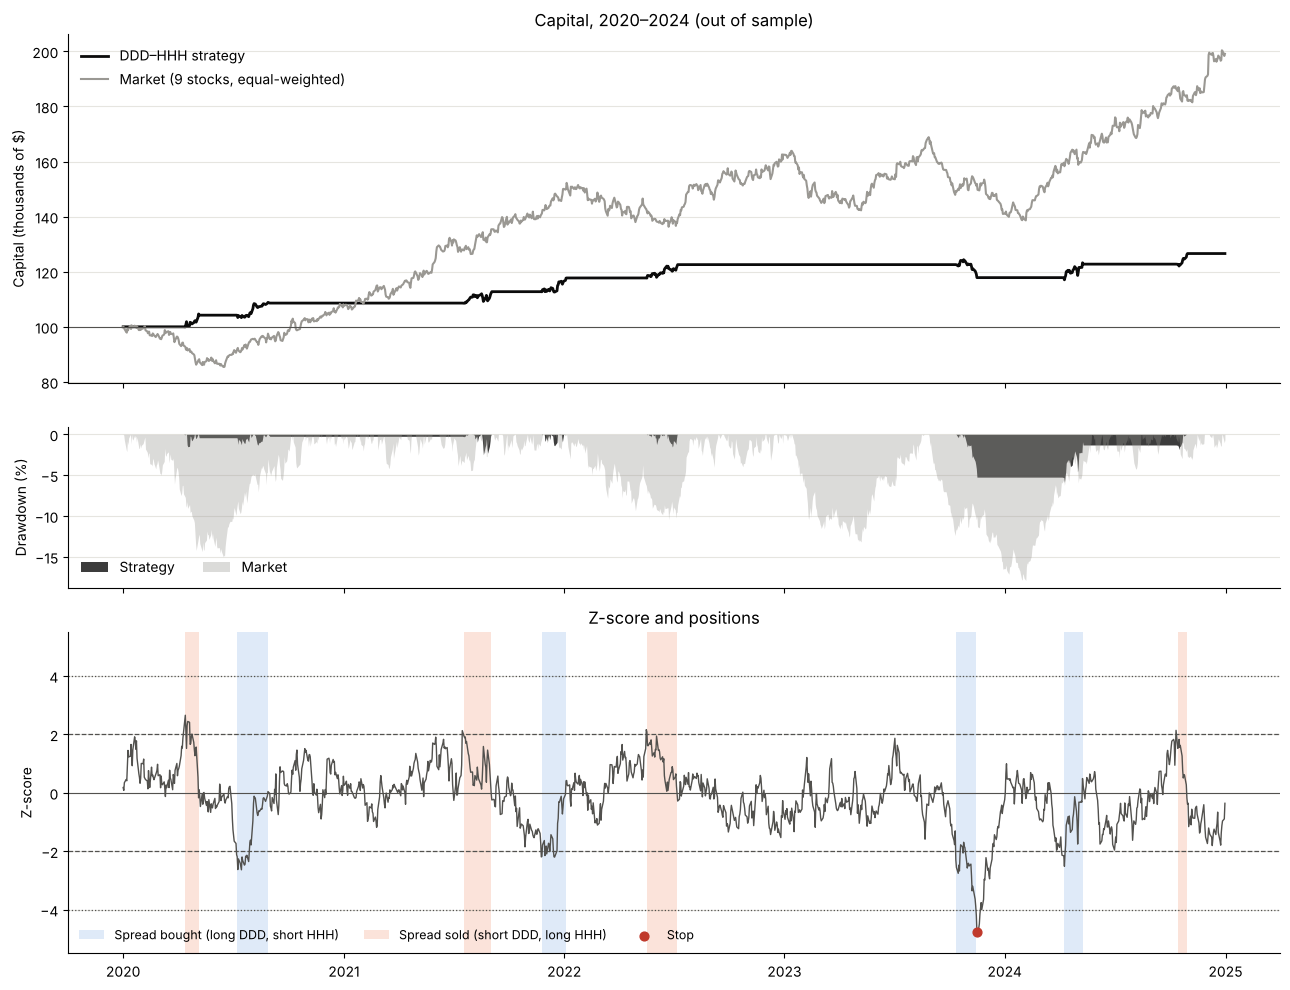

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, gridspec_kw={"height_ratios": [1.3, 0.6, 1.2]})

ax = axes[0]
ax.plot(eq_oos.index, eq_oos / 1e3, color=COLORS["Strategy"], linewidth=2, label="DDD–HHH strategy")
ax.plot(eq_mkt.index, eq_mkt / 1e3, color=COLORS["Market"], linewidth=1.5, label="Market (9 stocks, equal-weighted)")
ax.axhline(initial_capital / 1e3, color=GRAY, linewidth=0.8)
ax.set_ylabel(r"Capital (thousands of \$)")
ax.set_title("Capital, 2020–2024 (out of sample)")
ax.legend(frameon=False, loc="upper left")
style_ax(ax)

ax = axes[1]
for eq, name in [(eq_oos, "Strategy"), (eq_mkt, "Market")]:
    ax.fill_between(eq.index, 100 * (eq / eq.cummax() - 1), 0, color=COLORS[name], alpha=0.35 if name == "Market" else 0.8, linewidth=0, label=name)
ax.set_ylabel("Drawdown (%)")
ax.legend(frameon=False, loc="lower left", ncol=2)
style_ax(ax)

ax = axes[2]
z_t = zscore.loc[TEST]
ax.plot(z_t.index, z_t, color=GRAY, linewidth=1)
ax.fill_between(z_t.index, -5.5, 5.5, where=pos_oos > 0, color=COLORS["DDD"], alpha=0.15, linewidth=0, label="Spread bought (long DDD, short HHH)")
ax.fill_between(z_t.index, -5.5, 5.5, where=pos_oos < 0, color=COLORS["HHH"], alpha=0.18, linewidth=0, label="Spread sold (short DDD, long HHH)")
for level, style in [(2, "--"), (-2, "--"), (4, ":"), (-4, ":")]:
    ax.axhline(level, color=GRAY, linestyle=style, linewidth=0.9)
ax.axhline(0, color=GRAY, linewidth=0.8)
stops = trades_oos[trades_oos["reason"] == "stop"]
ax.scatter(stops["exit"], stops["z_exit"], color="#c0392b", zorder=5, s=40, label="Stop")
ax.set_ylim(-5.5, 5.5)
ax.set_ylabel("Z-score")
ax.set_title("Z-score and positions")
ax.legend(frameon=False, loc="lower left", ncol=3, fontsize=9)
style_ax(ax)
plt.tight_layout(); plt.show()

In [19]:
cols = ["entry", "exit", "side", "z_entry", "z_exit", "reason", "duration (days)", "P&L ($)", "return"]
view = trades_oos[cols].copy()
view.index = range(1, len(view) + 1)
view["entry"] = view["entry"].dt.date
view["exit"] = view["exit"].dt.date
view.style.format({"z_entry": "{:+.2f}", "z_exit": "{:+.2f}", "P&L ($)": "{:+,.0f}", "return": "{:+.2%}"}) \
    .set_caption("Trades, 2020–2024 (z_entry and z_exit: z-score on the execution day, the day after the signal)")

,entry,exit,side,z_entry,z_exit,reason,duration (days),P&L ($),return
1,2020-04-13,2020-05-06,sell spread,+2.65,+0.10,target,17,"+4,272",+4.27%
2,2020-07-08,2020-08-31,buy spread,-2.19,-0.03,target,38,"+4,442",+4.26%
3,2021-07-19,2021-09-03,sell spread,+1.93,-0.25,target,34,"+4,196",+3.87%
4,2021-11-25,2022-01-05,buy spread,-2.18,+0.42,target,29,"+5,035",+4.47%
5,2022-05-18,2022-07-08,sell spread,+2.08,-0.28,target,37,"+4,900",+4.16%
6,2023-10-13,2023-11-16,buy spread,-2.55,-4.77,stop,24,"-4,661",-3.80%
7,2024-04-08,2024-05-10,buy spread,-2.16,+0.26,target,24,"+4,955",+4.21%
8,2024-10-14,2024-10-30,sell spread,+1.52,-0.39,target,12,"+3,910",+3.19%


- **Profit of \$26,597 over five years** (+26.6%, i.e. +4.8% per year), with a volatility of only 3.7%. 7 of 8 trades are winners, each earning about 4% of capital, as expected in 5.1. The **Sharpe of 1.28** is lower than in formation (1.54), which is normal out of sample, but it remains good: the strategy did not collapse.
- **Risk is low and independent of the market.** The worst drawdown is −5.9%, versus −17.9% for the market. The correlation with the market is 0.03: the profit does not come from stocks rising in general.
- **The market earned more in absolute terms** (+99.1%) over a very bullish period, with a comparable Sharpe (1.16), but with about three times the volatility and a drawdown three times larger. The two play different roles: the strategy is an *uncorrelated* source of return to add to a portfolio, not a substitute for stocks.
- **The stop fired once, in October–November 2023.** After entering at z ≈ −2.5, the spread kept widening to about −4.9, never seen in formation. The strategy closed the position with a loss of 3.8% of capital (the only losing trade), then, per the rule, did not re-enter until |z| was back below 2. The spread then reverted to its mean, without us. In hindsight, the stop cost money (section 6.4), but there was no way to know at the time that the relationship would hold. It is the price of insurance against a break in cointegration.
- **Capital is deployed only 16% of the time.** The rest of the time it sits idle (and earns nothing in this simulation). This is an important limitation, discussed in section 8.

### 6.2 Did the relationship hold?

Only now do we rerun the cointegration tests on the test period, and re-estimate β on 2020–2024 to compare it with the one we used.

In [20]:
test_lp = log_prices.loc[TEST]
rows = []
for a, b in [("DDD", "HHH"), ("BBB", "CCC")]:
    _, beta_form, _ = fit_spread(a, b, FORMATION)
    _, beta_test, _ = fit_spread(a, b, TEST)
    rows.append({
        "Pair": f"{a}–{b}",
        "p-value 2015–2019": max(coint(form[a], form[b])[1], coint(form[b], form[a])[1]),
        "p-value 2020–2024": max(coint(test_lp[a], test_lp[b])[1], coint(test_lp[b], test_lp[a])[1]),
        "β 2015–2019": beta_form,
        "β 2020–2024": beta_test,
    })
ols_level_form = sm.OLS(prices.loc[FORMATION, "DDD"], sm.add_constant(prices.loc[FORMATION, "HHH"])).fit()
ols_level_test = sm.OLS(prices.loc[TEST, "DDD"], sm.add_constant(prices.loc[TEST, "HHH"])).fit()

stability = pd.DataFrame(rows).set_index("Pair")
print(f"DDD–HHH half-life: {HALF_LIFE:.1f} days in formation, {half_life(spread.loc[TEST]):.1f} days in test")
print(f"For comparison, β estimated on raw prices (not log prices): {ols_level_form.params.iloc[1]:.3f} in formation, {ols_level_test.params.iloc[1]:.3f} in test")
stability.style.format(fmt_p, subset=["p-value 2015–2019", "p-value 2020–2024"]).format("{:.3f}", subset=["β 2015–2019", "β 2020–2024"]) \
    .set_caption("Stability of cointegration")

DDD–HHH half-life: 13.6 days in formation, 15.1 days in test
For comparison, β estimated on raw prices (not log prices): 1.101 in formation, 1.030 in test


,p-value 2015–2019,p-value 2020–2024,β 2015–2019,β 2020–2024
Pair,,,,
DDD–HHH,5e-06,2e-05,0.791,0.791
BBB–CCC,0.0338,0.7971,0.726,0.672


- **DDD–HHH is still cointegrated in 2020–2024** (p-value still tiny), and β re-estimated on the test period alone is practically identical to the formation one (0.791 in both cases). The half-life is also stable (about 14–15 days). This is why parameters frozen in 2019 still work in 2024.
- **BBB–CCC, the false positive from section 3.2, is not cointegrated at all anymore** (high p-value). The Bonferroni correction was right to discard it.
- β estimated on raw prices changes more (from 1.10 to 1.03) than β estimated on log prices: working in logs gives a more stable relationship.

### 6.3 Does the profit come from the pair? Placebo test

If the strategy made money on any pair, choosing the pair would be pointless, and the profit might come from a flaw in the simulation. So we apply **exactly the same rules** (spread estimated on 2015–2019, same thresholds) to the other 35 pairs, over 2020–2024.

Other pairs: median Sharpe 0.13, 16 of 35 lose money, 4 wipe out the capital, median drawdown -26%
DDD–HHH    : Sharpe 1.28 (rank 1 of 36), drawdown -5.9% (rank 2 of 36, 1 = smallest)


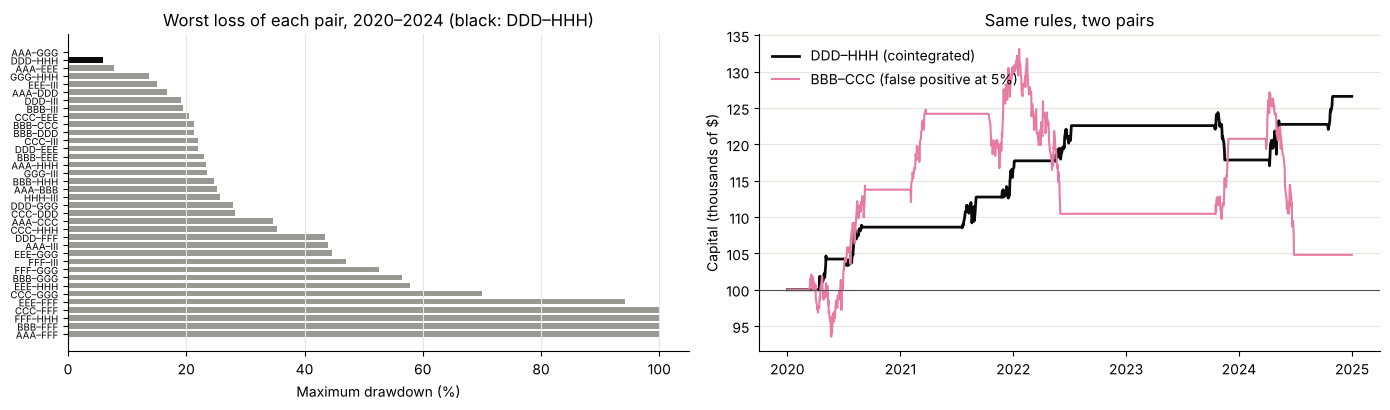

In [21]:
placebo_rows, placebo_eq = [], {}
for a, b in PAIRS:
    al, be, _ = fit_spread(a, b, FORMATION)
    s = log_prices[a] - be * log_prices[b] - al
    z = (s - s.loc[FORMATION].mean()) / s.loc[FORMATION].std()
    eq, pos, tr = backtest(a, b, z.loc[TEST], be)
    placebo_eq[f"{a}–{b}"] = eq
    mm = metrics(eq) if eq.iloc[-1] > 0 and eq.std() > 0 else None     # no measure if ruined or no trade
    placebo_rows.append({
        "Pair": f"{a}–{b}",
        "Total return": eq.iloc[-1] / initial_capital - 1,
        "Sharpe ratio": mm["Sharpe ratio"] if mm is not None else np.nan,
        "Maximum drawdown": (eq / eq.cummax() - 1).min(),
        "Ruined": eq.iloc[-1] <= 0,
    })
placebo = pd.DataFrame(placebo_rows).set_index("Pair")
others = placebo.drop("DDD–HHH")

print(f"Other pairs: median Sharpe {others['Sharpe ratio'].median():.2f}, "
      f"{(others['Total return'] < 0).sum()} of 35 lose money, {others['Ruined'].sum()} wipe out the capital, "
      f"median drawdown {others['Maximum drawdown'].median():.0%}")
print(f"DDD–HHH    : Sharpe {placebo.loc['DDD–HHH', 'Sharpe ratio']:.2f} (rank {int(placebo['Sharpe ratio'].rank(ascending=False)['DDD–HHH'])} of 36), "
      f"drawdown {placebo.loc['DDD–HHH', 'Maximum drawdown']:.1%} (rank {int(placebo['Maximum drawdown'].rank(ascending=False)['DDD–HHH'])} of 36, 1 = smallest)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
dd = placebo["Maximum drawdown"].sort_values()
ax.barh(range(len(dd)), -100 * dd.values, color=[COLORS["Strategy"] if p == "DDD–HHH" else COLORS["Market"] for p in dd.index], height=0.7)
ax.set_yticks(range(len(dd)), dd.index, fontsize=7)
ax.set_xlabel("Maximum drawdown (%)")
ax.set_title("Worst loss of each pair, 2020–2024 (black: DDD–HHH)")
ax.grid(axis="x", color=SHADE); ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.plot(eq_oos.index, eq_oos / 1e3, color=COLORS["Strategy"], linewidth=2, label="DDD–HHH (cointegrated)")
ax.plot(placebo_eq["BBB–CCC"].index, placebo_eq["BBB–CCC"] / 1e3, color=COLORS["BBB–CCC"], linewidth=1.5, label="BBB–CCC (false positive at 5%)")
ax.axhline(initial_capital / 1e3, color=GRAY, linewidth=0.8)
ax.set_ylabel(r"Capital (thousands of \$)")
ax.set_title("Same rules, two pairs")
ax.legend(frameon=False, loc="upper left")
style_ax(ax)
plt.tight_layout(); plt.show()

- **DDD–HHH has the best Sharpe of the 36 pairs, and the 2nd smallest drawdown** (only AAA–GGG does better, because it made no trade at all). On the others, the same rules give a median Sharpe of 0.13, a median drawdown of −25.7%, and 4 pairs lose the entire capital: without cointegration, a spread can widen indefinitely and the stop is not always enough (prices jump past it).
- **BBB–CCC**, which passed the 5% threshold without correction, returns +4.8% over five years (Sharpe 0.15, drawdown of −21.3%), with heavy losses along the way.
- Conclusion: **the profit comes from the cointegration of DDD–HHH**, not from the strategy's mechanics. The statistical test in section 3 was the most important decision.

### 6.4 Sensitivity to choices

We change **one** parameter at a time and measure the effect on 2020–2024. These results are looked at *after* the test: they are not used to pick better parameters, but to see whether the result hinges on a precise setting.

In [22]:
def run_variant(**kwargs):
    z = kwargs.pop("z", zscore.loc[TEST])
    beta = kwargs.pop("beta", BETA)
    eq, pos, tr = backtest("DDD", "HHH", z, beta, **kwargs)
    m = metrics(eq, pos, tr)
    return m[["Total return", "Sharpe ratio", "Maximum drawdown", "Number of trades"]]

# Variant: spread re-estimated every January 1 with all data available up to then (expanding window)
z_refit, beta_refit = [], []
for year in range(2020, 2025):
    hist = slice("2015-01-01", f"{year - 1}-12-31")
    al, be, _ = fit_spread("DDD", "HHH", hist)
    s = log_prices["DDD"] - be * log_prices["HHH"] - al
    yr = slice(f"{year}-01-01", f"{year}-12-31")
    z_refit.append((s.loc[yr] - s.loc[hist].mean()) / s.loc[hist].std())
    beta_refit.append(pd.Series(be, index=s.loc[yr].index))
z_refit, beta_refit = pd.concat(z_refit), pd.concat(beta_refit)

variants = {
    "Chosen strategy": {},
    "Costs: 0": dict(cost=0.0),
    "Costs: 0.10% per leg": dict(cost=0.0010),
    "Costs: 0.25% per leg": dict(cost=0.0025),
    "Borrow cost: 1% per year": dict(borrow=0.01),
    "Borrow cost: 3% per year": dict(borrow=0.03),
    "No stop": dict(stop=np.inf),
    "Stop at 3.5": dict(stop=3.5),
    "Stop at 5": dict(stop=5.0),
    "Entry at 1.5": dict(entry=1.5),
    "Entry at 2.5": dict(entry=2.5),
    "Exit at ±0.5": dict(exit=0.5),
    "β and z re-estimated yearly": dict(z=z_refit, beta=beta_refit),
}
sens = pd.DataFrame({name: run_variant(**kw) for name, kw in variants.items()}).T
sens.style.format({"Total return": "{:+.1%}", "Sharpe ratio": "{:.2f}", "Maximum drawdown": "{:.1%}", "Number of trades": "{:.0f}"}) \
    .set_caption("Sensitivity, 2020–2024 (one change at a time)")

,Total return,Sharpe ratio,Maximum drawdown,Number of trades
Chosen strategy,+26.6%,1.28,-5.9%,8
Costs: 0,+27.6%,1.33,-5.8%,8
Costs: 0.10% per leg,+25.6%,1.24,-6.0%,8
Costs: 0.25% per leg,+22.7%,1.10,-6.3%,8
Borrow cost: 1% per year,+26.1%,1.26,-5.9%,8
Borrow cost: 3% per year,+25.1%,1.22,-6.0%,8
No stop,+37.1%,1.63,-5.3%,8
Stop at 3.5,+28.6%,1.38,-4.4%,8
Stop at 5,+37.1%,1.63,-5.3%,8
Entry at 1.5,+44.6%,1.35,-5.8%,17


In [23]:
grid_oos = sharpe_grid(TEST)
grid_oos.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=2.5) \
    .set_caption("Out-of-sample Sharpe ratio by threshold (chosen rule: entry 2, exit 0)")

,exit -0.5,exit 0.0,exit 0.5,exit 1.0
entry 1.5,1.22,1.35,1.37,1.49
entry 1.75,1.20,1.42,1.30,1.38
entry 2.0,1.22,1.28,1.29,1.06
entry 2.25,0.85,0.87,0.77,0.69
entry 2.5,0.88,0.90,0.81,0.73


- **The result does not hinge on a precise setting.** Every threshold combination gives a positive out-of-sample Sharpe (from 0.69 to 1.49). The chosen thresholds (1.28) are neither the best nor the worst. High entry thresholds (2.25 and 2.5) do worse, mostly because they produce fewer trades. A lower threshold (1.5) would have produced more trades and more profit (+44.6%), with a similar Sharpe.
- **Costs matter little**, because there are few trades and each targets a spread move of about 6%. Even at 0.25% per leg (five times the base assumption), the strategy stays profitable. Borrow cost also has little effect, since we are in a position only about 16% of the time.
- **The stop cost money over this period**: without a stop (or with a stop at 5, never reached), the late-2023 trade would eventually have come back, and the return rises to +37.1%. A tighter stop (3.5) also does slightly better than 4, because it cuts the loss earlier. These differences come from **a single episode**: no rule can be drawn from it. On non-cointegrated pairs (section 6.3), the opposite scenario happens. We keep the stop.
- **Re-estimating β every year changes almost nothing**, which confirms the relationship is stable: freezing the parameters in 2019 was not a handicap.

## 7. Assumptions and their effect on the results

| # | Assumption | Why we believe it | Effect if it is wrong |
|---|---|---|---|
| 1 | The DDD–HHH relationship estimated in 2015–2019 remains valid afterwards | Cointegration still significant in 2020–2024; identical β (6.2); yearly re-estimation changes nothing (6.4) | If the relationship breaks, the spread no longer reverts. The ±4 stop limits the loss to about 4% of capital per trade |
| 2 | We can trade at the close of the day after the signal | Common assumption for daily data | The real execution price differs slightly: equivalent to an extra cost (tested up to 0.25%) |
| 3 | Transaction costs of 0.05% per leg | Order of magnitude for liquid stocks | Small: profitable even at 0.25% (6.4) |
| 4 | Short selling always possible, with no borrow cost | Simplifying assumption | Small: 3% per year of borrow cost removes little (6.4). But if HHH or DDD became impossible to borrow, the strategy would be blocked |
| 5 | No interest on idle cash or on short-sale proceeds | Conservative choice | The result is **underestimated**: capital sits idle more than 80% of the time and would earn the risk-free rate |
| 6 | Capital covers 100% of gross exposure (no leverage) | Prudence | Return scales with leverage. At 2× (allowed under usual margin rules), return and drawdown roughly double; the Sharpe does not change |
| 7 | Prices are reliable, with no dividends or splits to adjust | Inspection (section 2): no suspicious jumps | An excluded dividend would slightly distort the spread; no visible effect here |

## 8. Limitations

- **Few trades.** 8 trades in five years out of sample, 18 in ten years. Enough to see that the strategy works, but too few to estimate its return precisely: one or two more losing trades would change the result noticeably. The standard error of a Sharpe ratio estimated over five years is about 0.6: the Sharpe of 1.28 is therefore (just) significantly positive, but its true value could be anywhere between about 0.1 and 2.5.
- **The data are most likely synthetic** (calendar without holidays, a single clearly cointegrated pair, a perfectly stable relationship over ten years). On real stocks, cointegration relationships often break: a merger, a change in strategy at one of the two companies, a sector shock. Such perfect stability would be rare.
- **Capital is poorly used.** It is deployed only about 16% of the time. In practice, one would combine several pairs (in a universe larger than nine stocks) to keep capital working continuously, or use moderate leverage.
- **The stop is a trade-off.** It protects against a break in the relationship, but it cost money here. An episode like late 2023 shows the spread can go further than anything seen in formation; a more severe episode could jump past the stop (price gap), and the loss would be larger than planned.
- **No information about the companies.** We do not know why DDD and HHH are linked. In practice, one would check that there is a lasting economic reason (same sector, same customers, same costs), which gives confidence that the link will survive.
- **Choosing among 36 pairs is still a form of search**: even with Bonferroni, part of the quality observed in formation comes from selection. That is why only the test period counts when judging the strategy.

## 9. Conclusion

Out of the 36 possible pairs, **DDD and HHH is the only truly cointegrated pair**: it passes two different tests, even after correcting for multiple testing, while the runner-up (BBB–CCC) is a false positive that later disappears. The spread $\ln(\text{DDD}) - 0.79 \ln(\text{HHH})$ reverts to its mean with a half-life of about three weeks.

A simple strategy (enter at ±2 standard deviations, exit when the spread returns to its mean, cut at ±4), set with 2015–2019 and applied unchanged to 2020–2024, **turns \$100,000 into \$126,597**, with a Sharpe of 1.28, a maximum drawdown of −5.9% and almost zero correlation with the market. The result holds up to costs, thresholds and parameter re-estimation, and the same rules fail on non-cointegrated pairs: the profit really does come from the relationship between DDD and HHH.

The main caveats are the small number of trades and the most likely synthetic nature of the data. On real stocks, one would need to monitor continuously that the relationship holds, and diversify across several pairs.

In [24]:
final = summary.loc[["Final capital ($)", "P&L ($)", "Total return", "Annualized return", "Annualized volatility",
                     "Sharpe ratio", "Maximum drawdown", "Correlation with market", "Number of trades", "Win rate"]]
show_metrics(final, "Final result — DDD–HHH pair, $100,000 starting capital")

,"Strategy, 2015–2019 (formation)","Strategy, 2020–2024 (test)","Market, 2020–2024"
Final capital ($),"140,624","126,597","199,084"
P&L ($),"40,624","26,597","99,084"
Total return,40.6%,26.6%,99.1%
Annualized return,7.1%,4.8%,14.8%
Annualized volatility,4.5%,3.7%,12.5%
Sharpe ratio,1.54,1.28,1.16
Maximum drawdown,-4.2%,-5.9%,-17.9%
Correlation with market,-0.02,0.03,1.00
Number of trades,10,8,—
Win rate,100.0%,87.5%,—
